# 04 - Clustering

Groups of applications with similar product profiles, using four methods: K-Means++, Agglomerative clustering
(Ward linkage), Gaussian Mixture Models and DBSCAN. The clusters are built without the label; the failure rate
is only used afterwards to describe them.

## Settings

In [1]:
K_RANGE = range(5, 51, 5)    # k values tried for K-Means and GMM
SELECT_SAMPLE = 50_000       # rows used to fit K-Means while choosing k
SAMPLE_SIZE = 15_000         # sample for Agglomerative, DBSCAN, silhouette and ARI
SVD_COMPONENTS = 30          # text components before PCA
PCA_VARIANCE = 0.80          # share of variance kept by PCA
DBSCAN_MIN_SAMPLES = 20
RANDOM_STATE = 42

In [2]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score, average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.base import clone

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from features import feature_groups
from modeling import make_preprocessor, make_models

FIG, OUT = ROOT / "figures", ROOT / "outputs"
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

## 1. Representation

Each application is described by what it protects:
the 45 Nice class columns (binary) and the English goods description (TF-IDF, reduced with TruncatedSVD).
The text components are L2-normalized and both parts are standardized, then PCA keeps 80% of the variance
(reducing dimensions before clustering removes noise, as discussed in class).
Everything is fit on the training years only, so the same transformation can be applied to the test years
in the cluster-as-feature experiment.

In [3]:
feats = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet")
train = feats[feats["is_train"]].reset_index(drop=True)
test = feats[~feats["is_train"]].reset_index(drop=True)
nice_cols = [f"nice_{k}" for k in range(1, 46)]

# numbers and the words "class" / "included" appear in almost every description, so they are removed
stop_words = list(ENGLISH_STOP_WORDS | {"class", "classes", "included", "including"})
tfidf = TfidfVectorizer(stop_words=stop_words, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",
                        min_df=5, max_features=20000, sublinear_tf=True)
svd = TruncatedSVD(n_components=SVD_COMPONENTS, random_state=RANDOM_STATE)
scaler = StandardScaler()

def represent(df, fit=False):
    tf = tfidf.fit_transform(df["goods_text"]) if fit else tfidf.transform(df["goods_text"])
    txt = svd.fit_transform(tf) if fit else svd.transform(tf)
    X = np.hstack([df[nice_cols].to_numpy(float), normalize(txt)])
    return scaler.fit_transform(X) if fit else scaler.transform(X)

X_train_full = represent(train, fit=True)
pca = PCA(n_components=PCA_VARIANCE, random_state=RANDOM_STATE).fit(X_train_full)
Z_train = pca.transform(X_train_full)
Z_test = pca.transform(represent(test))
print(f"{X_train_full.shape[1]} columns -> {Z_train.shape[1]} PCA components "
      f"({pca.explained_variance_ratio_.sum():.0%} of the variance)")

75 columns -> 40 PCA components (81% of the variance)


## 2. Choosing k: elbow and silhouette (K-Means++), BIC (GMM)

K-Means is fit on a 50,000-row sample for each k, and the silhouette is computed on a 15,000-row sample.

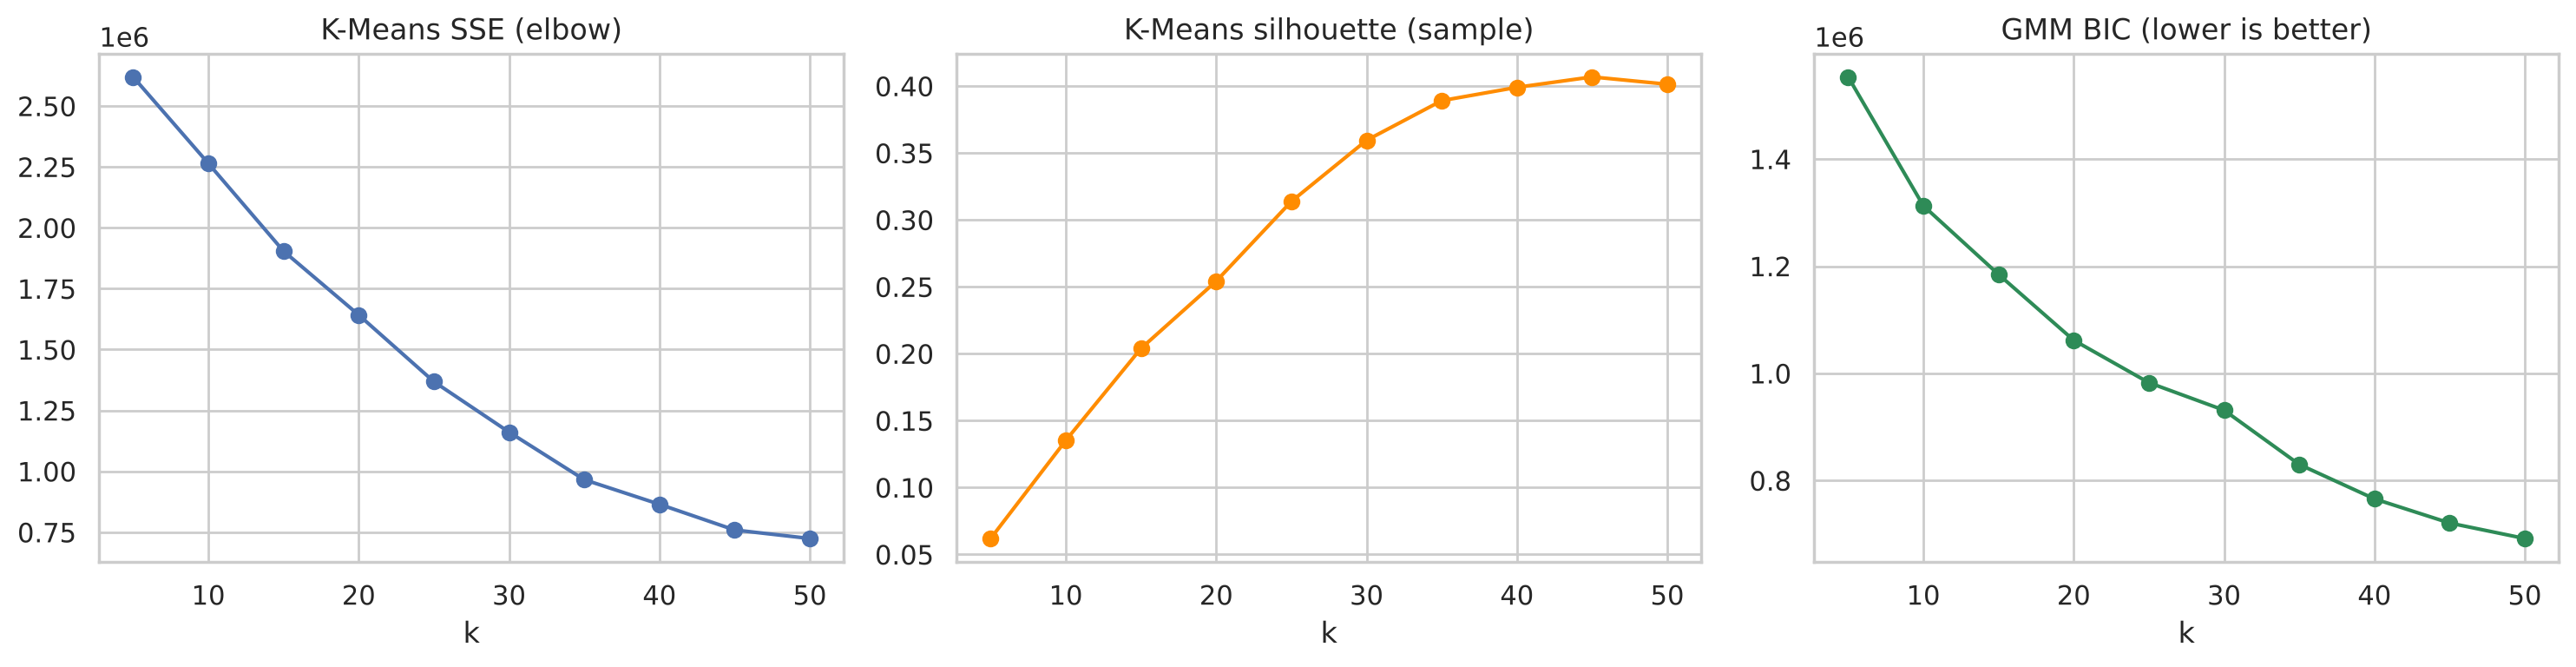

,SSE,silhouette,GMM BIC
k,,,
5,2619517.616,0.062,1553299.826
10,2264626.149,0.135,1312848.106
15,1904337.449,0.204,1184668.019
20,1642157.838,0.254,1061817.743
25,1368206.606,0.314,982592.860
30,1161022.655,0.359,931182.852
35,965746.623,0.389,829922.270
40,864710.202,0.399,765702.396
45,759130.613,0.407,720594.774


In [4]:
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(Z_train), SAMPLE_SIZE, replace=False)
Z_sample = Z_train[sample_idx]
Z_select = Z_train[rng.choice(len(Z_train), SELECT_SAMPLE, replace=False)]

rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=3, random_state=RANDOM_STATE).fit(Z_select)
    gmm = GaussianMixture(n_components=k, covariance_type="diag", random_state=RANDOM_STATE).fit(Z_sample)
    rows.append({"k": k, "SSE": km.inertia_,
                 "silhouette": silhouette_score(Z_sample, km.predict(Z_sample)),
                 "GMM BIC": gmm.bic(Z_sample)})
k_table = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
k_table["SSE"].plot(ax=axes[0], marker="o", title="K-Means SSE (elbow)")
k_table["silhouette"].plot(ax=axes[1], marker="o", color="darkorange", title="K-Means silhouette (sample)")
k_table["GMM BIC"].plot(ax=axes[2], marker="o", color="seagreen", title="GMM BIC (lower is better)")
plt.tight_layout()
plt.savefig(FIG / "choosing_k.png", dpi=120)
plt.show()
k_table.round(3)

In [5]:
K = int(k_table["silhouette"].idxmax())
K_GMM = int(k_table["GMM BIC"].idxmin())
print("k chosen by silhouette for K-Means / Agglomerative:", K)
print("k with the lowest BIC for GMM:", K_GMM)

k chosen by silhouette for K-Means / Agglomerative: 45
k with the lowest BIC for GMM: 50


## 3. Fit the four methods

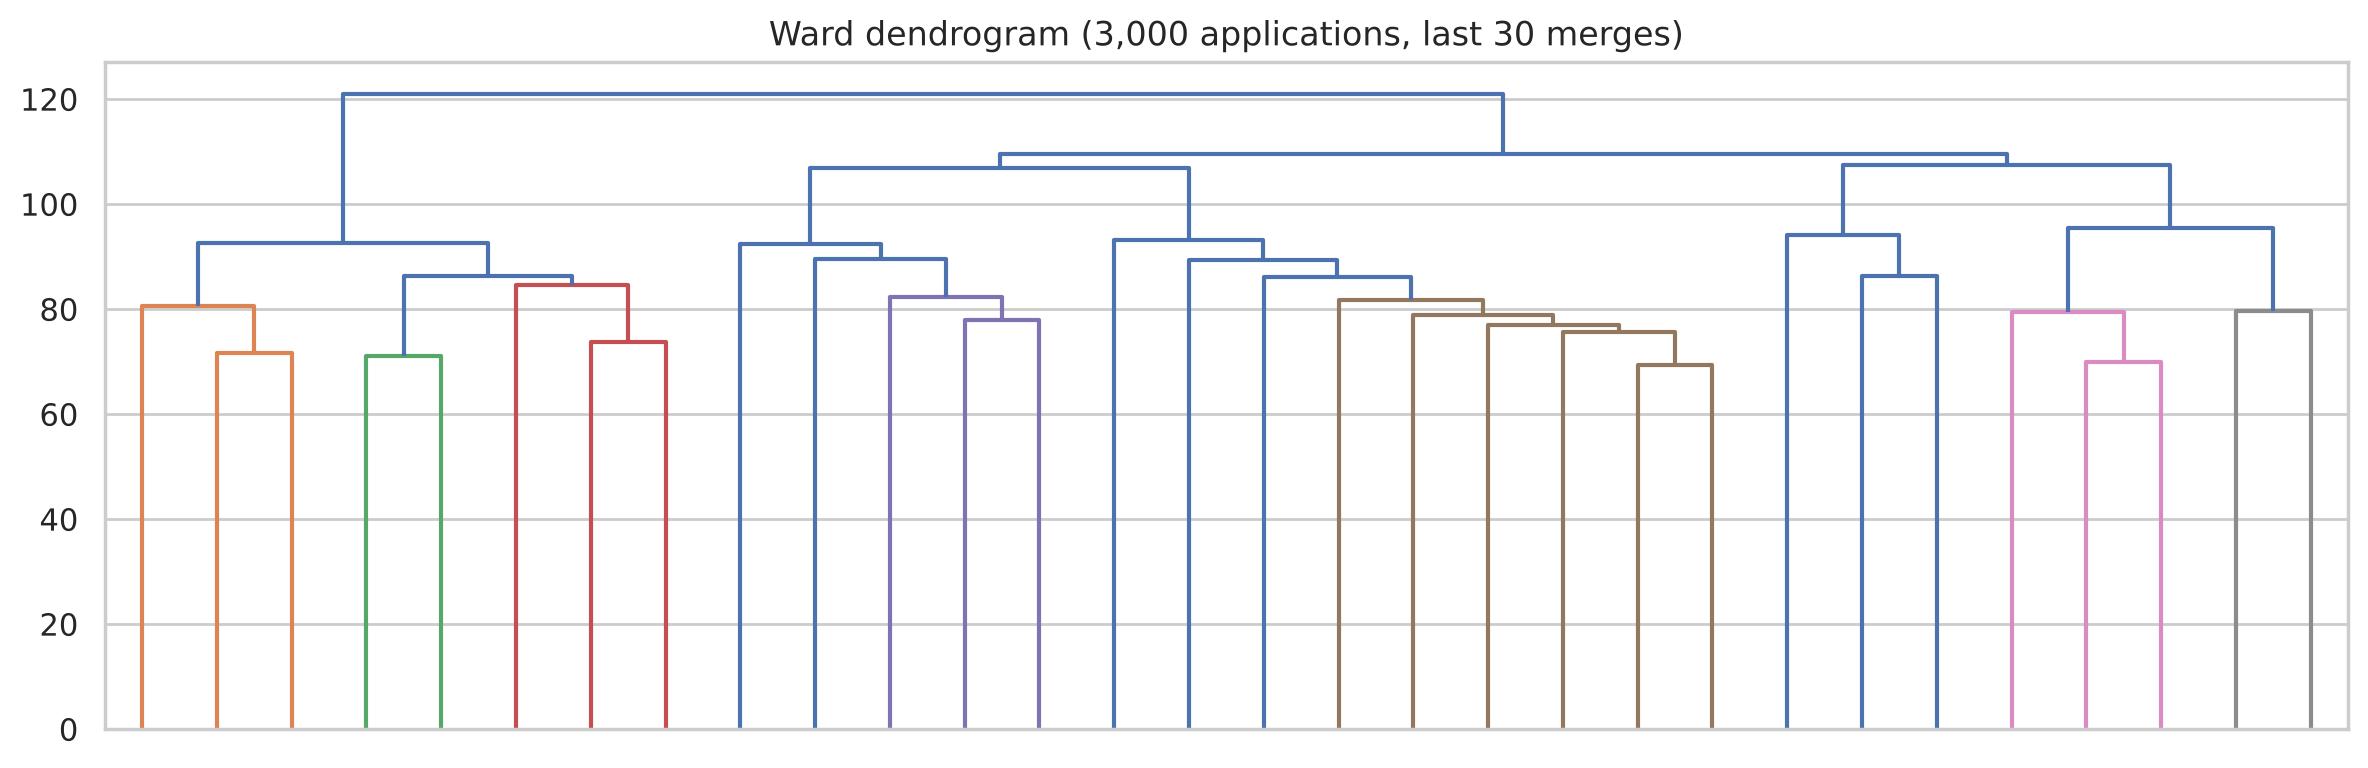

In [6]:
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(Z_train)
gmm = GaussianMixture(n_components=K_GMM, covariance_type="diag", random_state=RANDOM_STATE).fit(Z_sample)

# Agglomerative needs the full distance structure, so it runs on the sample
agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z_sample)

fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(linkage(Z_sample[:3000], method="ward"), truncate_mode="lastp", p=30, ax=ax, no_labels=True)
ax.set_title("Ward dendrogram (3,000 applications, last 30 merges)")
plt.tight_layout()
plt.savefig(FIG / "dendrogram.png", dpi=120)
plt.show()

**DBSCAN parameters.** `min_samples` is fixed and `eps` is read from the k-distance plot: the distance to the
`min_samples`-th neighbour, sorted. The bend of the curve separates dense areas from sparse points.

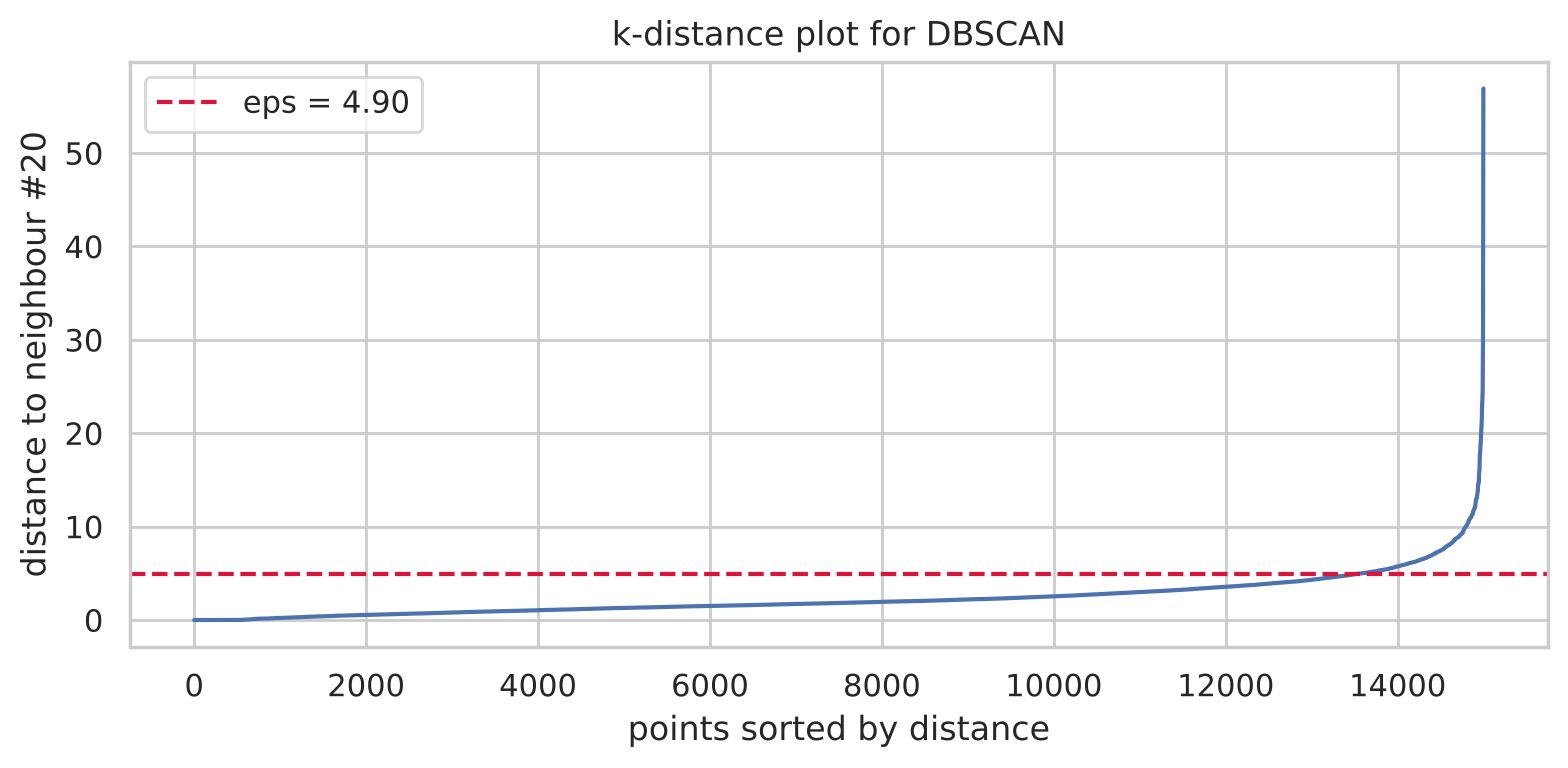

DBSCAN clusters: 19 | noise points: 5.8%


In [7]:
nn = NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(Z_sample)
kdist = np.sort(nn.kneighbors(Z_sample)[0][:, -1])
EPS = float(np.quantile(kdist, 0.90))   # bend of the curve: top 10% of distances count as sparse

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(kdist)
ax.axhline(EPS, color="crimson", ls="--", label=f"eps = {EPS:.2f}")
ax.set(xlabel="points sorted by distance", ylabel=f"distance to neighbour #{DBSCAN_MIN_SAMPLES}",
       title="k-distance plot for DBSCAN")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "dbscan_kdistance.png", dpi=120)
plt.show()

dbscan = DBSCAN(eps=EPS, min_samples=DBSCAN_MIN_SAMPLES).fit(Z_sample)
db_labels = dbscan.labels_
print("DBSCAN clusters:", len(set(db_labels)) - (-1 in db_labels), "| noise points:", f"{(db_labels == -1).mean():.1%}")

## 4. Comparing the methods

All four are compared on the same sample. Silhouette for DBSCAN is computed without its noise points.
ARI measures how much two methods agree (1 = identical partitions, 0 = chance level).

,clusters,silhouette,largest cluster share
method,,,
K-Means++,45,0.401,0.063
Agglomerative (Ward),45,0.399,0.070
GMM,50,0.314,0.078
DBSCAN,19,0.108,0.876


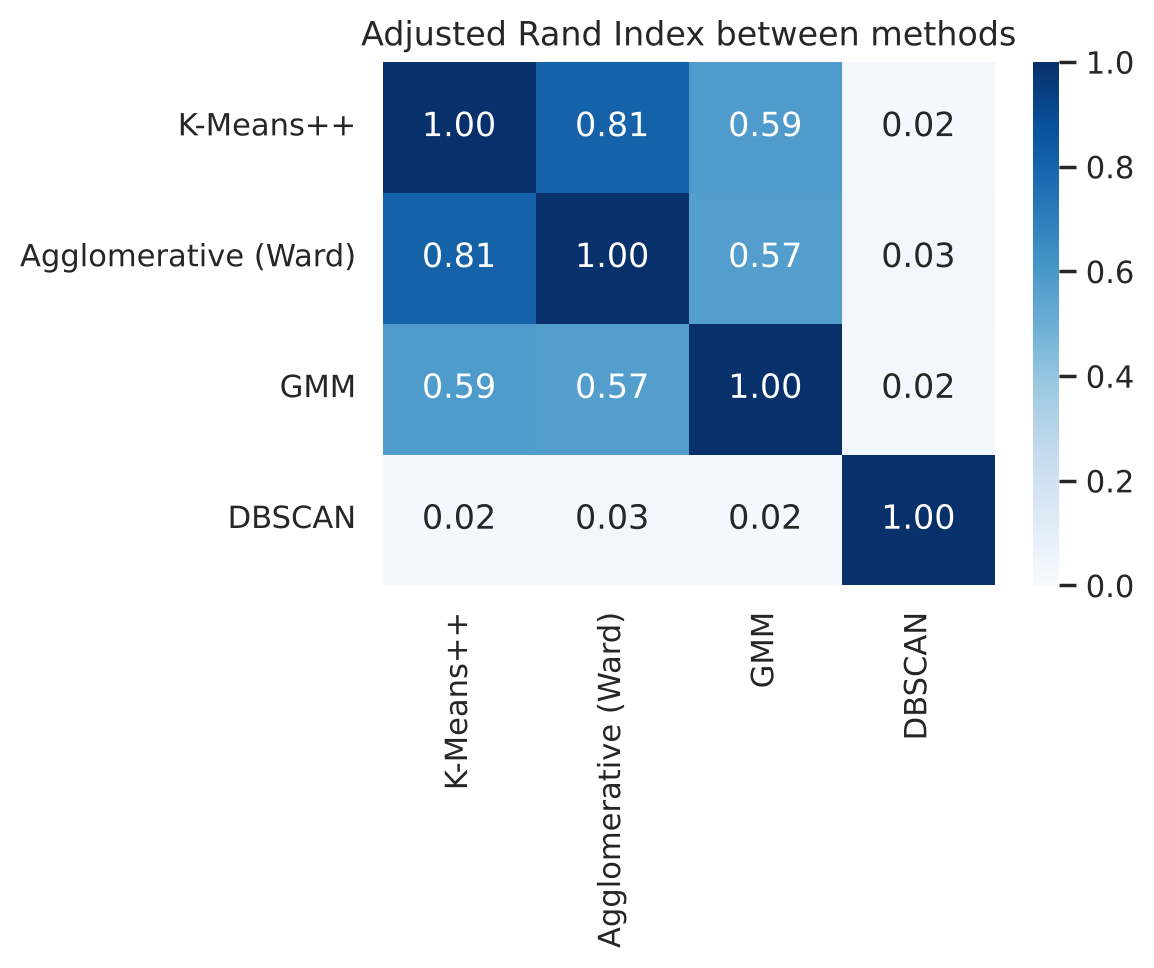

In [8]:
labels = {
    "K-Means++": kmeans.predict(Z_sample),
    "Agglomerative (Ward)": agg.labels_,
    "GMM": gmm.predict(Z_sample),
    "DBSCAN": db_labels,
}
comparison = []
for name, lab in labels.items():
    mask = lab != -1 if name == "DBSCAN" else np.ones(len(lab), bool)
    comparison.append({"method": name, "clusters": len(set(lab[mask])),
                       "silhouette": silhouette_score(Z_sample[mask], lab[mask]),
                       "largest cluster share": pd.Series(lab[mask]).value_counts(normalize=True).iloc[0]})
display(pd.DataFrame(comparison).set_index("method").round(3))

ari = pd.DataFrame({a: {b: adjusted_rand_score(labels[a], labels[b]) for b in labels} for a in labels})
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Adjusted Rand Index between methods")
plt.tight_layout()
plt.savefig(FIG / "ari_between_methods.png", dpi=120)
plt.show()

**Choosing k.** There is no clear elbow. The silhouette keeps rising until about 45 clusters (0.41) and then flattens.
45 is also the number of Nice classes, which already tells us something: the strongest structure in this representation
is the Nice classification itself. The GMM BIC is still going down at 50, the edge of the range, so we use 50 for GMM.

**Comparison.** K-Means++ and Agglomerative (Ward) give almost the same partition (ARI 0.81) and the best silhouette
(about 0.40). GMM agrees with them only partly (ARI about 0.58), and its membership probabilities are almost always close to 1,
so the soft assignment adds little here. DBSCAN puts 88% of the points in one dense cluster and agrees with none of the others
(ARI about 0.02). Density doesn't separate these groups well, but its noise points are useful (section 6).

## 5. What the K-Means clusters contain, and how often they fail

In [9]:
train["cluster"] = kmeans.labels_
base = train["failed"].mean()
terms = np.array(tfidf.get_feature_names_out())

def top_terms(c, n=6):
    # mean TF-IDF of the cluster's goods descriptions
    docs = tfidf.transform(train.loc[train["cluster"] == c, "goods_text"].sample(
        min(3000, (train["cluster"] == c).sum()), random_state=RANDOM_STATE))
    return ", ".join(terms[np.asarray(docs.mean(axis=0)).ravel().argsort()[::-1][:n]])

profile = []
for c, g in train.groupby("cluster"):
    nice_share = g[nice_cols].mean().sort_values(ascending=False)
    profile.append({"cluster": c, "size": len(g), "failure_rate": g["failed"].mean(),
                    "lift": g["failed"].mean() / base,
                    "main Nice classes": ", ".join(f"{n.split('_')[1]} ({v:.0%})" for n, v in nice_share.head(3).items()),
                    "top goods terms": top_terms(c)})
profile = pd.DataFrame(profile).set_index("cluster").sort_values("failure_rate", ascending=False)
profile.round(3)

,size,failure_rate,lift,main Nice classes,top goods terms
cluster,,,,,
3,6748,0.236,1.547,"42 (98%), 9 (8%), 35 (5%)","computer, services, design, software, developm..."
17,5019,0.218,1.426,"38 (97%), 9 (23%), 42 (16%)","services, telecommunication, telecommunication..."
15,3899,0.218,1.425,"43 (98%), 35 (6%), 30 (4%)","food, services, drink, providing, restaurant, ..."
37,8859,0.211,1.380,"35 (99%), 42 (3%), 9 (2%)","business, advertising, services, management, r..."
39,2249,0.198,1.295,"45 (100%), 42 (33%), 35 (33%)","services, legal, social, security, property, c..."
42,7964,0.192,1.257,"41 (99%), 9 (6%), 35 (4%)","entertainment, education, services, training, ..."
10,4500,0.186,1.218,"29 (99%), 30 (27%), 32 (8%)","milk, meat, products, fish, vegetables, edible"
0,9411,0.184,1.203,"25 (98%), 35 (4%), 9 (2%)","clothing, footwear, headgear, shoes, shirts, hats"
1,6548,0.183,1.196,"30 (99%), 35 (1%), 43 (1%)","confectionery, coffee, chocolate, tea, pastry,..."


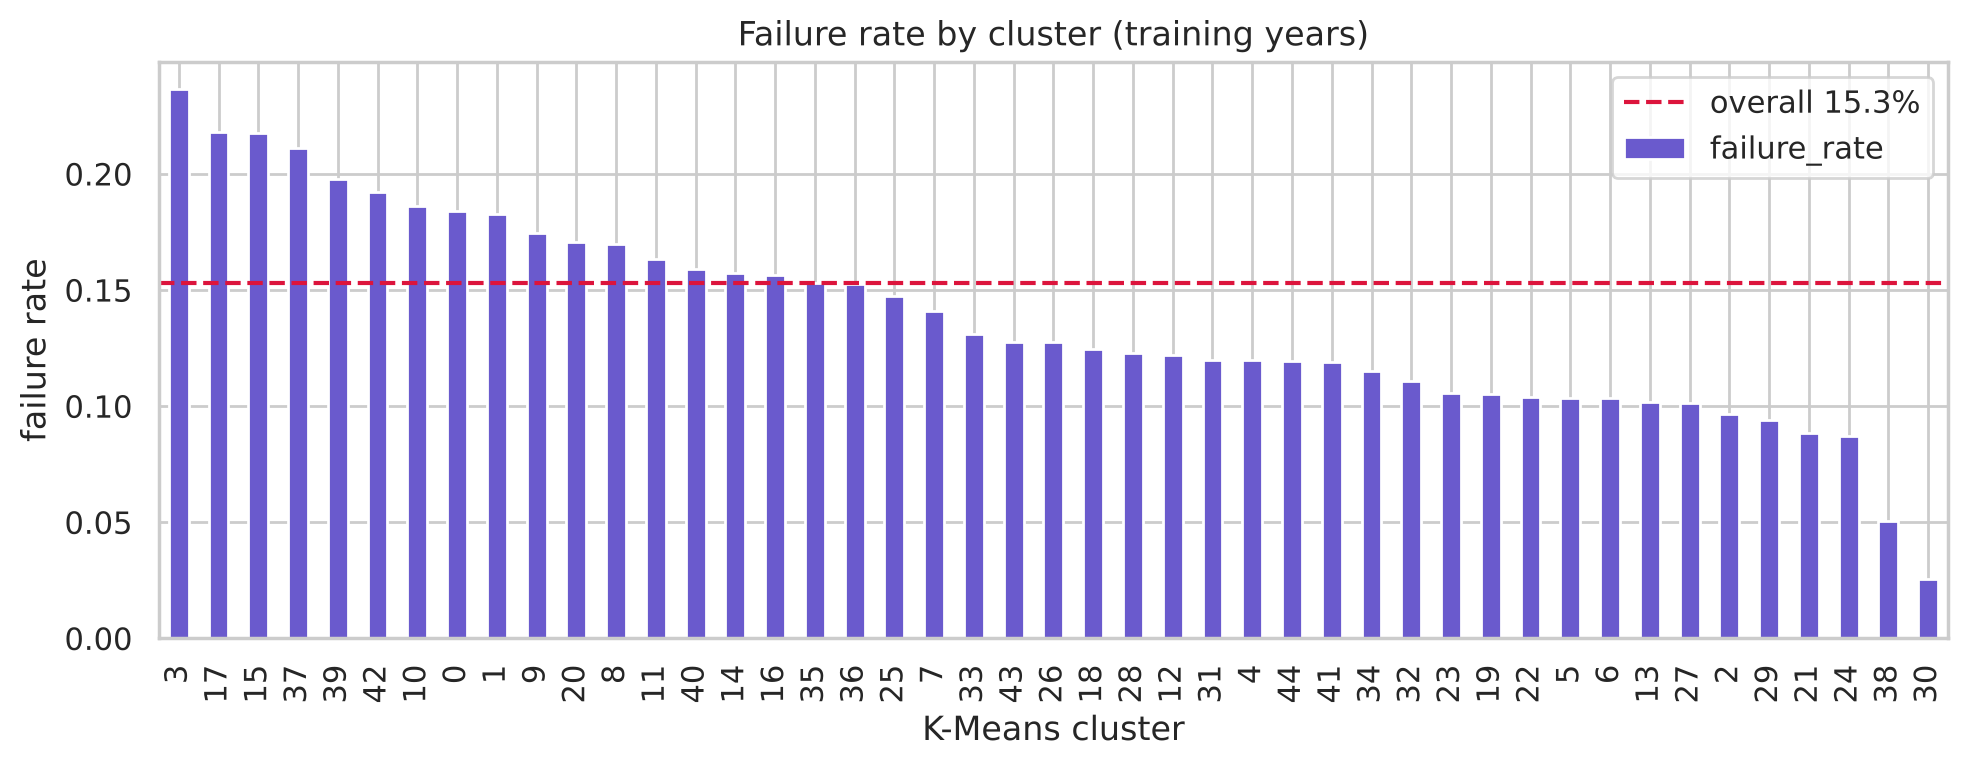

GMM: median membership probability 1.00, 0.4% of points have no cluster above 0.6


In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
profile["failure_rate"].plot.bar(ax=ax, color="slateblue")
ax.axhline(base, color="crimson", ls="--", label=f"overall {base:.1%}")
ax.set(xlabel="K-Means cluster", ylabel="failure rate", title="Failure rate by cluster (training years)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "failure_by_cluster.png", dpi=120)
plt.show()

gmm_conf = gmm.predict_proba(Z_sample).max(axis=1)
print(f"GMM: median membership probability {np.median(gmm_conf):.2f}, "
      f"{(gmm_conf < 0.6).mean():.1%} of points have no cluster above 0.6")

**Clusters and failure.** Almost every cluster is built around one Nice class, and the goods text splits some classes further.
Service clusters fail the most: computer services (class 42, 24%), telecommunications (38), restaurants (43) and
advertising and business (35), all around 21-22%. Chemicals, paints, lubricants and industrial materials fail the least (9-10%).
Class 5 is split into three clusters with very different rates: pharmaceuticals for treating diseases (5%),
general pharmaceutical preparations (10%) and food supplements (15%). The text separates groups that the class number alone can't.

## 6. Anomalies: DBSCAN noise points

Applications DBSCAN couldn't place in any dense area. Do they fail more often?

In [11]:
sample_failed = train.loc[sample_idx, "failed"].to_numpy()
anomaly = pd.DataFrame({"noise": db_labels == -1, "failed": sample_failed,
                        "n_classes": train.loc[sample_idx, "n_classes"].to_numpy()})
anomaly.groupby("noise").agg(n=("failed", "size"), failure_rate=("failed", "mean"),
                             mean_classes=("n_classes", "mean")).round(3)

,n,failure_rate,mean_classes
noise,,,
False,14124,0.157,1.193
True,876,0.112,5.098


**Anomalies.** The 5.8% of applications DBSCAN marks as noise cover about 5 Nice classes on average, compared with about 1
for the rest. These broad applications fail less often (11% vs 16%), which matches what we saw for the number of classes in notebook 01.

## 7. Does the cluster help the classifier?

LightGBM with the tuned parameters from notebook 03, with and without the K-Means cluster as an extra
categorical feature. K-Means was fit on training years only and assigns test applications by nearest centroid.

In [12]:
best_params = json.loads((OUT / "best_params.json").read_text())["LightGBM"]
numeric, categorical, text = feature_groups(feats.columns)
train["kmeans_cluster"] = kmeans.labels_.astype(str)
test["kmeans_cluster"] = kmeans.predict(Z_test).astype(str)
X_cols = numeric + categorical + [text, "kmeans_cluster"]

rows = []
for with_cluster in [False, True]:
    cats = categorical + (["kmeans_cluster"] if with_cluster else [])
    pipe = Pipeline([("pre", make_preprocessor(numeric, cats, text)),
                     ("model", clone(make_models()["LightGBM"]))]).set_params(**best_params)
    pipe.fit(train[X_cols], train["failed"])
    p = pipe.predict_proba(test[X_cols])[:, 1]
    rows.append({"features": "with cluster" if with_cluster else "without cluster",
                 "test ROC-AUC": roc_auc_score(test["failed"], p),
                 "test PR-AUC": average_precision_score(test["failed"], p)})
pd.DataFrame(rows).set_index("features").round(4)

,test ROC-AUC,test PR-AUC
features,,
without cluster,0.7236,0.3437
with cluster,0.7219,0.3393


**Cluster as a feature.** Adding the cluster doesn't help (test PR-AUC 0.344 without it, 0.339 with it).
That makes sense: the model already gets the Nice classes and the goods text that the clusters are built from.

In [13]:
profile.to_csv(OUT / "kmeans_cluster_profile.csv")
print("saved")

saved
